# AI-Assisted Community Awareness Campaign Generator

## Phase 1: Baseline Models

Objective:
Train and compare baseline machine learning
models for SDG multi-label text classification
using TF-IDF features.

1. Import the libraries

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


2. Load the dataset

In [3]:

dataset = load_dataset("UNDP/sdgi-corpus")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Columns:", train_df.columns.tolist())

train_df.head(3)


Training rows: 5880
Test rows: 1470
Columns: ['text', 'embedding', 'labels', 'metadata']


,text,embedding,labels,metadata
0,END POVERTY\r\nIN ALL ITS FORMS \r\nEVERYWHERE...,"[-0.0066694277, -0.0135167073, 0.0032988016000...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."
1,PONER FIN A LA POBREZA\r\nEN TODAS SUS FORMAS ...,"[-0.0120671522, -0.0182979926, 0.0129378373000...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."
2,End poverty in all its \r\nforms everywhere\r\...,"[-0.0063659865, -0.0047052945, 0.0053374511000...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."


4. Prepare the text and multi-label targets

In [4]:

# Prepare the text data
X_text = train_df["text"].fillna("").astype(str)

# Convert each row's labels into a list
y_labels = train_df["labels"].apply(
    lambda labels: list(labels)
).tolist()

# Convert label lists into a binary indicator matrix
mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(y_labels)

print("Number of training examples:", len(X_text))
print("Number of unique labels:", len(mlb.classes_))
print("Target matrix shape:", Y.shape)
print("First example's labels:", y_labels[0])
print("First example's binary targets:", Y[0])


Number of training examples: 5880
Number of unique labels: 17
Target matrix shape: (5880, 17)
First example's labels: [np.int64(1)]
First example's binary targets: [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


5. Create training and validation sets

In [5]:

X_train, X_val, Y_train, Y_val = train_test_split(
    X_text,
    Y,
    test_size=0.20,
    random_state=42
)

print("Training text examples:", len(X_train))
print("Validation text examples:", len(X_val))
print("Training target shape:", Y_train.shape)
print("Validation target shape:", Y_val.shape)


Training text examples: 4704
Validation text examples: 1176
Training target shape: (4704, 17)
Validation target shape: (1176, 17)


6. Check label coverage

In [6]:

train_label_counts = Y_train.sum(axis=0)
val_label_counts = Y_val.sum(axis=0)

label_coverage = pd.DataFrame({
    "SDG label": mlb.classes_,
    "Training examples": train_label_counts.astype(int),
    "Validation examples": val_label_counts.astype(int)
})

display(label_coverage)

print("Labels absent from training:", (train_label_counts == 0).sum())
print("Labels absent from validation:", (val_label_counts == 0).sum())


,SDG label,Training examples,Validation examples
0,1,345,107
1,2,342,95
2,3,464,114
3,4,414,118
4,5,389,98
5,6,326,69
6,7,331,89
7,8,446,102
8,9,369,98
9,10,387,98


Labels absent from training: 0
Labels absent from validation: 0


7. Build the baseline models
   
We'll compare three models:
- Dummy Classifier — a simple reference point that predicts the most frequent outcome for each label.
- Logistic Regression — a standard text-classification baseline.
- Linear SVM — another strong baseline for TF-IDF text features.
   
We'll use TF-IDF with unigrams and bigrams, and OneVsRestClassifier to handle the 17 labels independently.
Each model will learn its TF-IDF vocabulary from the training data only.

In [8]:

models = {
    "Dummy Baseline": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", OneVsRestClassifier(
            DummyClassifier(strategy="most_frequent")
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", OneVsRestClassifier(
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        ))
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", OneVsRestClassifier(
            LinearSVC(class_weight="balanced")
        ))
    ])
}

print("Defined models:", list(models.keys()))


Defined models: ['Dummy Baseline', 'Logistic Regression', 'Linear SVM']


8. Train and evaluate the models

In [9]:

results = []

for name, model in models.items():
    print(f"Training: {name}...")

    model.fit(X_train, Y_train)
    predictions = model.predict(X_val)

    scores = {
        "Model": name,
        "Micro F1": f1_score(
            Y_val, predictions, average="micro", zero_division=0
        ),
        "Macro F1": f1_score(
            Y_val, predictions, average="macro", zero_division=0
        ),
        "Micro Precision": precision_score(
            Y_val, predictions, average="micro", zero_division=0
        ),
        "Micro Recall": recall_score(
            Y_val, predictions, average="micro", zero_division=0
        )
    }

    results.append(scores)
    print(f"Finished: {name}")

results_df = pd.DataFrame(results).sort_values(
    by="Macro F1", ascending=False
)

display(results_df.round(4))


Training: Dummy Baseline...
Finished: Dummy Baseline
Training: Logistic Regression...
Finished: Logistic Regression
Training: Linear SVM...
Finished: Linear SVM


,Model,Micro F1,Macro F1,Micro Precision,Micro Recall
2,Linear SVM,0.8168,0.8200,0.8409,0.7941
1,Logistic Regression,0.7850,0.7924,0.7339,0.8437
0,Dummy Baseline,0.0000,0.0000,0.0000,0.0000


9. Plot the validation macro-F1 scores

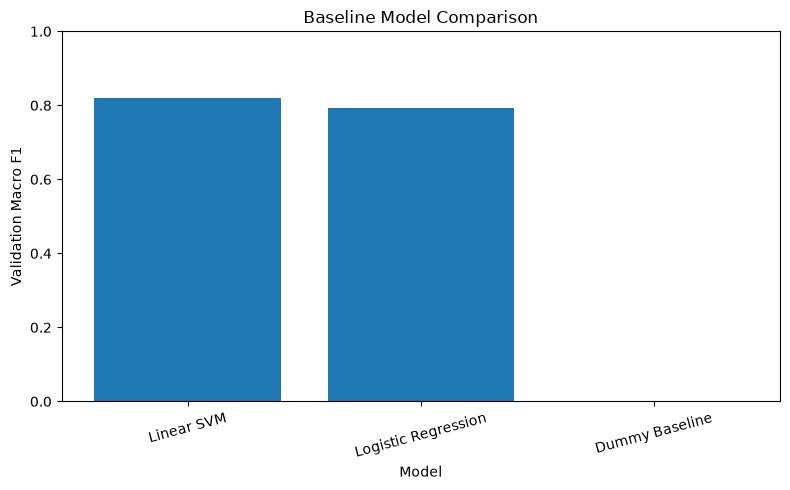

In [10]:

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Macro F1"]
)

plt.ylabel("Validation Macro F1")
plt.xlabel("Model")
plt.title("Baseline Model Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


10. Select the best model

In [11]:

best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

print("Selected model:", best_name)
print(
    "Validation Macro F1:",
    round(results_df.iloc[0]["Macro F1"], 4)
)


Selected model: Linear SVM
Validation Macro F1: 0.82


11. Evaluate on the official test set

In [12]:

# Prepare the official test data
X_test_text = test_df["text"].fillna("").astype(str)

Y_test = mlb.transform(
    test_df["labels"].apply(list).tolist()
)

# Predict using the selected model
test_predictions = best_model.predict(X_test_text)

# Calculate final test metrics
test_macro_f1 = f1_score(
    Y_test, test_predictions, average="macro", zero_division=0
)
test_micro_f1 = f1_score(
    Y_test, test_predictions, average="micro", zero_division=0
)
test_precision = precision_score(
    Y_test, test_predictions, average="micro", zero_division=0
)
test_recall = recall_score(
    Y_test, test_predictions, average="micro", zero_division=0
)

print("Selected model:", best_name)
print("Test Macro F1:", round(test_macro_f1, 4))
print("Test Micro F1:", round(test_micro_f1, 4))
print("Test Micro Precision:", round(test_precision, 4))
print("Test Micro Recall:", round(test_recall, 4))


Selected model: Linear SVM
Test Macro F1: 0.7154
Test Micro F1: 0.7215
Test Micro Precision: 0.7301
Test Micro Recall: 0.7131


In [1]:

from sklearn.metrics import classification_report
import pandas as pd

# Get the classification report for each SDG label
report = classification_report(
    y_test,
    y_test_pred,
    target_names=[f"SDG {label}" for label in mlb.classes_],
    output_dict=True,
    zero_division=0
)

# Convert the report into a readable DataFrame
sdg_report = pd.DataFrame(report).T

# Display only the individual SDG results
sdg_report = sdg_report.iloc[:len(mlb.classes_)]

display(sdg_report)

# Save the report
sdg_report.to_csv(
    "notebooks/per_sdg_classification_report.csv",
    index=True
)

print("Per-SDG classification report saved successfully!")


NameError: name 'y_test' is not defined

In [13]:

print(classification_report(
    Y_test,
    test_predictions,
    labels=np.arange(len(mlb.classes_)),
    target_names=[str(label) for label in mlb.classes_],
    zero_division=0
))


              precision    recall  f1-score   support

           1       0.81      0.67      0.73       123
           2       0.81      0.66      0.73        97
           3       0.73      0.69      0.71       132
           4       0.74      0.72      0.73       134
           5       0.71      0.67      0.69        81
           6       0.66      0.81      0.73        80
           7       0.63      0.64      0.64        64
           8       0.75      0.71      0.73       168
           9       0.69      0.66      0.68       140
          10       0.73      0.70      0.72       170
          11       0.70      0.84      0.76       238
          12       0.72      0.66      0.69       136
          13       0.71      0.74      0.72       129
          14       0.81      0.62      0.71        48
          15       0.85      0.61      0.71        83
          16       0.80      0.73      0.76       119
          17       0.71      0.74      0.73       163

   micro avg       0.73   

12. Save the evaluation results

In [14]:

test_results = pd.DataFrame([{
    "model": best_name,
    "validation_macro_f1": float(
        results_df.iloc[0]["Macro F1"]
    ),
    "test_macro_f1": float(test_macro_f1),
    "test_micro_f1": float(test_micro_f1),
    "test_micro_precision": float(test_precision),
    "test_micro_recall": float(test_recall),
    "random_state": 42,
    "tfidf_max_features": 20000,
    "tfidf_ngram_range": "(1, 2)",
    "training_examples": len(X_train),
    "validation_examples": len(X_val),
    "test_examples": len(test_df),
    "number_of_labels": len(mlb.classes_)
}])

test_results.to_csv(
    "baseline_evaluation_results.csv",
    index=False
)

display(test_results.round(4))
print("Saved baseline_evaluation_results.csv")


,model,validation_macro_f1,test_macro_f1,test_micro_f1,test_micro_precision,test_micro_recall,random_state,tfidf_max_features,tfidf_ngram_range,training_examples,validation_examples,test_examples,number_of_labels
0,Linear SVM,0.82,0.7154,0.7215,0.7301,0.7131,42,20000,"(1, 2)",4704,1176,1470,17


Saved baseline_evaluation_results.csv


13. Save your trained model

In [15]:

import joblib
import json
from pathlib import Path

# Create a folder for trained model artifacts
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the complete trained pipeline
model_path = model_dir / "linear_svm_baseline.joblib"
joblib.dump(best_model, model_path)

# Save label mapping and configuration
config = {
    "selected_model": best_name,
    "label_ids": [int(label) for label in mlb.classes_],
    "validation_macro_f1": float(
        results_df.iloc[0]["Macro F1"]
    ),
    "test_macro_f1": float(test_macro_f1),
    "test_micro_f1": float(test_micro_f1),
    "test_micro_precision": float(test_precision),
    "test_micro_recall": float(test_recall),
    "random_state": 42
}

config_path = model_dir / "baseline_config.json"
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("Saved model:", model_path)
print("Saved configuration:", config_path)
print("Model files:", [p.name for p in model_dir.iterdir()])


Saved model: models/linear_svm_baseline.joblib
Saved configuration: models/baseline_config.json
Model files: ['linear_svm_baseline.joblib', 'baseline_config.json']


14. Create an MLflow tracking cell

In [25]:

import mlflow

mlflow.set_experiment("sdg-text-classification-baselines")

with mlflow.start_run(run_name="linear-svm-tfidf-baseline"):
    mlflow.log_param("model", best_name)
    mlflow.log_param("vectorizer", "TF-IDF")
    mlflow.log_param("ngram_range", "(1, 2)")
    mlflow.log_param("max_features", 20000)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("training_examples", len(X_train))
    mlflow.log_param("validation_examples", len(X_val))
    mlflow.log_param("test_examples", len(test_df))
    mlflow.log_param("number_of_labels", len(mlb.classes_))

    # Validation metrics (4)
    mlflow.log_metric(
        "validation_macro_f1",
        float(results_df[results_df["Model"] == best_name].iloc[0]["Macro F1"])
    )
    mlflow.log_metric(
        "validation_micro_f1",
        float(results_df[results_df["Model"] == best_name].iloc[0]["Micro F1"])
    )
    mlflow.log_metric(
        "validation_micro_precision",
        float(results_df[results_df["Model"] == best_name].iloc[0]["Micro Precision"])
    )
    mlflow.log_metric(
        "validation_micro_recall",
        float(results_df[results_df["Model"] == best_name].iloc[0]["Micro Recall"])
    )

    # Test metrics (4)
    mlflow.log_metric("test_macro_f1", float(test_macro_f1))
    mlflow.log_metric("test_micro_f1", float(test_micro_f1))
    mlflow.log_metric("test_micro_precision", float(test_precision))
    mlflow.log_metric("test_micro_recall", float(test_recall))

    mlflow.log_artifact("baseline_evaluation_results.csv")
    mlflow.log_artifact("models/baseline_config.json")

print("MLflow experiment logged successfully!")


MLflow experiment logged successfully!


In [23]:

import mlflow

mlflow.set_experiment("sdg-text-classification-baselines")

# Calculate and log results for the other two models
Y_test_eval = mlb.transform(test_df["labels"])

for model_name in ["Logistic Regression", "Dummy Baseline"]:
    model = models[model_name]
    predictions = model.predict(test_df["text"])

    from sklearn.metrics import f1_score, precision_score, recall_score

    test_macro = f1_score(
        Y_test_eval, predictions, average="macro", zero_division=0
    )
    test_micro = f1_score(
        Y_test_eval, predictions, average="micro", zero_division=0
    )
    test_precision = precision_score(
        Y_test_eval, predictions, average="micro", zero_division=0
    )
    test_recall = recall_score(
        Y_test_eval, predictions, average="micro", zero_division=0
    )

    # Get the validation metrics already calculated in the notebook
    row = results_df[results_df["Model"] == model_name].iloc[0]

    with mlflow.start_run(run_name=model_name):
        mlflow.log_param("model", model_name)
        mlflow.log_param("vectorizer", "TF-IDF")
        mlflow.log_param("ngram_range", "(1, 2)")
        mlflow.log_param("max_features", 20000)
        mlflow.log_param("random_state", 42)
        mlflow.log_param("training_examples", len(X_train))
        mlflow.log_param("validation_examples", len(X_val))
        mlflow.log_param("test_examples", len(test_df))
        mlflow.log_param("number_of_labels", len(mlb.classes_))

        mlflow.log_metric(
            "validation_macro_f1", float(row["Macro F1"])
        )
        mlflow.log_metric(
            "validation_micro_f1", float(row["Micro F1"])
        )
        mlflow.log_metric(
            "validation_micro_precision", float(row["Micro Precision"])
        )
        mlflow.log_metric(
            "validation_micro_recall", float(row["Micro Recall"])
        )

        mlflow.log_metric("test_macro_f1", float(test_macro))
        mlflow.log_metric("test_micro_f1", float(test_micro))
        mlflow.log_metric("test_micro_precision", float(test_precision))
        mlflow.log_metric("test_micro_recall", float(test_recall))

        mlflow.log_artifact("baseline_evaluation_results.csv")
        mlflow.log_artifact("models/baseline_config.json")

    print(f"MLflow logging completed: {model_name}")


MLflow logging completed: Logistic Regression
MLflow logging completed: Dummy Baseline


In [26]:

import mlflow
from sklearn.metrics import precision_score, recall_score

# Recalculate using the fitted Linear SVM and the held-out test set
Y_test_eval = mlb.transform(test_df["labels"])
svm_predictions = models["Linear SVM"].predict(test_df["text"])

correct_precision = precision_score(
    Y_test_eval, svm_predictions,
    average="micro", zero_division=0
)

correct_recall = recall_score(
    Y_test_eval, svm_predictions,
    average="micro", zero_division=0
)

print("Correct test micro precision:", correct_precision)
print("Correct test micro recall:", correct_recall)


Correct test micro precision: 0.7300583657587548
Correct test micro recall: 0.7130641330166271


In [27]:

from mlflow.tracking import MlflowClient

client = MlflowClient()

run_id = "45835dc9a9124a20947bca3fcd714491"

client.log_metric(
    run_id, "test_micro_precision", float(correct_precision)
)
client.log_metric(
    run_id, "test_micro_recall", float(correct_recall)
)

print("Linear SVM test precision and recall corrected!")


Linear SVM test precision and recall corrected!


TEST

In [17]:

import mlflow

print("Tracking URI:", mlflow.get_tracking_uri())

experiment = mlflow.get_experiment_by_name(
    "sdg-text-classification-baselines"
)

if experiment:
    print("Experiment name:", experiment.name)
    print("Experiment ID:", experiment.experiment_id)
    print("Artifact location:", experiment.artifact_location)
else:
    print("Named experiment not found in this tracking store.")


Tracking URI: sqlite:////Users/pavans/Projects%20%284th%20sem%29/5th-sem/community-awareness-generator/notebooks/mlflow.db
Experiment name: sdg-text-classification-baselines
Experiment ID: 1
Artifact location: /Users/pavans/Projects (4th sem)/5th-sem/community-awareness-generator/notebooks/mlruns/1


In [18]:

from pathlib import Path
import json

raw_dir = Path("../data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

for split in ["train", "test"]:
    output_path = raw_dir / f"{split}.jsonl"

    with output_path.open("w", encoding="utf-8") as f:
        for example in dataset[split]:
            record = {
                "text": example["text"],
                "labels": example["labels"],
                "metadata": example["metadata"]
            }
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    print(f"Saved {output_path}")


Saved ../data/raw/train.jsonl
Saved ../data/raw/test.jsonl


In [20]:

print("Models:", list(models.keys()))
print("Test data shape:", test_df.shape)
print("Test labels shape:", Y_test.shape if "Y_test" in globals() else "Y_test not found")
print("Label binarizer classes:", len(mlb.classes_))


Models: ['Dummy Baseline', 'Logistic Regression', 'Linear SVM']
Test data shape: (1470, 4)
Test labels shape: (1470, 17)
Label binarizer classes: 17


ML FLOW using Weights & Biases (W&B)

In [28]:
import wandb

wandb.login()

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice:  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter:  ········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /Users/pavans/.netrc
wandb: Currently logged in as: phoenixrising27623 (phoenixrising27623-pavan) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

Create a test experiment

In [29]:
import wandb

wandb.init(
    project="community-awareness-sdg-classifier",
    name="setup-test",
    notes="Experiment tracking for the UNDP SDG multi-label classification project"
)

wandb.finish()

Inspect your results CSV

In [30]:
import pandas as pd
from pathlib import Path

results_path = Path("baseline_evaluation_results.csv")

if not results_path.exists():
    results_path = Path("notebooks/baseline_evaluation_results.csv")

results_df = pd.read_csv(results_path)

print("File:", results_path.resolve())
print("Columns:", results_df.columns.tolist())
display(results_df)

File: /Users/pavans/Projects (4th sem)/5th-sem/community-awareness-generator/notebooks/baseline_evaluation_results.csv
Columns: ['model', 'validation_macro_f1', 'test_macro_f1', 'test_micro_f1', 'test_micro_precision', 'test_micro_recall', 'random_state', 'tfidf_max_features', 'tfidf_ngram_range', 'training_examples', 'validation_examples', 'test_examples', 'number_of_labels']


,model,validation_macro_f1,test_macro_f1,test_micro_f1,test_micro_precision,test_micro_recall,random_state,tfidf_max_features,tfidf_ngram_range,training_examples,validation_examples,test_examples,number_of_labels
0,Linear SVM,0.819987,0.715395,0.721461,0.730058,0.713064,42,20000,"(1, 2)",4704,1176,1470,17


In [31]:
print(results_df["model"].tolist())

['Linear SVM']


In [32]:
import wandb

svm_row = results_df.iloc[0]

run = wandb.init(
    project="community-awareness-sdg-classifier",
    name="linear-svm-tfidf-baseline",
    job_type="evaluation",
    notes="Existing Linear SVM baseline results on the UNDP SDGi corpus"
)

wandb.config.update({
    "model": str(svm_row["model"]),
    "random_state": int(svm_row["random_state"]),
    "tfidf_max_features": int(svm_row["tfidf_max_features"]),
    "tfidf_ngram_range": str(svm_row["tfidf_ngram_range"]),
    "training_examples": int(svm_row["training_examples"]),
    "validation_examples": int(svm_row["validation_examples"]),
    "test_examples": int(svm_row["test_examples"]),
    "number_of_labels": int(svm_row["number_of_labels"]),
})

run.log({
    "validation/macro_f1": float(svm_row["validation_macro_f1"]),
    "test/macro_f1": float(svm_row["test_macro_f1"]),
    "test/micro_f1": float(svm_row["test_micro_f1"]),
    "test/micro_precision": float(svm_row["test_micro_precision"]),
    "test/micro_recall": float(svm_row["test_micro_recall"]),
})

wandb.finish()

print("Linear SVM results logged to W&B.")

test/macro_f1,▁
test/micro_f1,▁
test/micro_precision,▁
test/micro_recall,▁
validation/macro_f1,▁
test/macro_f1,0.71539
test/micro_f1,0.72146
test/micro_precision,0.73006
test/micro_recall,0.71306
validation/macro_f1,0.81999


Linear SVM results logged to W&B.


In [2]:

import joblib
import pandas as pd
from pathlib import Path
from datasets import load_dataset
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import classification_report

# 1. Load the original dataset
dataset = load_dataset("UNDP/sdgi-corpus")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

# 2. Recreate the original label mapping
y_labels = train_df["labels"].apply(
    lambda labels: list(labels)
).tolist()

mlb = MultiLabelBinarizer()
mlb.fit(y_labels)

# 3. Prepare the official test labels
Y_test = mlb.transform(
    test_df["labels"].apply(list).tolist()
)

# 4. Load the already-trained model (no retraining)
model_path = Path("notebooks/models/linear_svm_baseline.joblib")

if not model_path.exists():
    model_path = Path("models/linear_svm_baseline.joblib")

model = joblib.load(model_path)

# 5. Generate predictions on the official test set
X_test_text = test_df["text"].fillna("").astype(str)
test_predictions = model.predict(X_test_text)

# 6. Generate per-SDG classification report
report = classification_report(
    Y_test,
    test_predictions,
    target_names=[f"SDG {label}" for label in mlb.classes_],
    output_dict=True,
    zero_division=0
)

# 7. Convert report to DataFrame
sdg_report = pd.DataFrame(report).T

sdg_report = sdg_report.loc[
    [f"SDG {label}" for label in mlb.classes_]
]

display(sdg_report)

# 8. Save CSV in the project notebooks folder
output_file = Path("notebooks/per_sdg_classification_report.csv")
output_file.parent.mkdir(parents=True, exist_ok=True)

sdg_report.to_csv(output_file, index=True)

print("\nClassification report saved!")
print("Location:", output_file.resolve())
print("File exists:", output_file.exists())
print("Number of SDG labels:", len(sdg_report))


,precision,recall,f1-score,support
SDG 1,0.805825,0.674797,0.734513,123.0
SDG 2,0.810127,0.659794,0.727273,97.0
SDG 3,0.728000,0.689394,0.708171,132.0
SDG 4,0.740458,0.723881,0.732075,134.0
SDG 5,0.710526,0.666667,0.687898,81.0
SDG 6,0.656566,0.812500,0.726257,80.0
SDG 7,0.630769,0.640625,0.635659,64.0
SDG 8,0.745342,0.714286,0.729483,168.0
SDG 9,0.688889,0.664286,0.676364,140.0
SDG 10,0.734568,0.700000,0.716867,170.0



Classification report saved!
Location: /Users/pavans/Projects (4th sem)/5th-sem/community-awareness-generator/notebooks/notebooks/per_sdg_classification_report.csv
File exists: True
Number of SDG labels: 17


In [3]:
from pathlib import Path
import shutil

source = Path("notebooks/per_sdg_classification_report.csv")
destination = Path("per_sdg_classification_report.csv")

if source.exists():
    shutil.move(str(source), str(destination))
    print("CSV moved successfully!")
else:
    print("Source CSV not found:", source.resolve())

print("Final location:", destination.resolve())
print("File exists:", destination.exists())

CSV moved successfully!
Final location: /Users/pavans/Projects (4th sem)/5th-sem/community-awareness-generator/notebooks/per_sdg_classification_report.csv
File exists: True


In [4]:

import pandas as pd

# Load the saved classification report
report_df = pd.read_csv(
    "per_sdg_classification_report.csv",
    index_col=0
)

# Select the three important metrics
sdg_analysis = report_df[
    ["precision", "recall", "f1-score", "support"]
].copy()

# Sort labels by F1-score
sdg_analysis = sdg_analysis.sort_values(
    by="f1-score",
    ascending=True
)

print("SDG performance sorted from lowest to highest F1:")
display(sdg_analysis)

# Calculate correlation between support and F1-score
correlation = sdg_analysis["support"].corr(
    sdg_analysis["f1-score"]
)

print("Correlation between support and F1-score:", round(correlation, 3))


SDG performance sorted from lowest to highest F1:


,precision,recall,f1-score,support
SDG 7,0.630769,0.640625,0.635659,64.0
SDG 9,0.688889,0.664286,0.676364,140.0
SDG 5,0.710526,0.666667,0.687898,81.0
SDG 12,0.720000,0.661765,0.689655,136.0
SDG 14,0.810811,0.625000,0.705882,48.0
SDG 3,0.728000,0.689394,0.708171,132.0
SDG 15,0.850000,0.614458,0.713287,83.0
SDG 10,0.734568,0.700000,0.716867,170.0
SDG 13,0.705882,0.744186,0.724528,129.0
SDG 6,0.656566,0.812500,0.726257,80.0


Correlation between support and F1-score: 0.502
